# Extracción web del catálogo histórico de glosas

Se extraen las tablas HTML de Mis Cuentas Médicas, transcripción del Anexo Técnico 6. Este catálogo permite agrupar motivos por concepto y estudiar su relación con la cartera. La fuente, el hash del HTML y los conteos de esta ejecución quedan en el registro adjunto.

In [1]:
import pathlib, sys, json
import pandas as pd
RAIZ = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(RAIZ / "scripts"))
import mapear_motivos as mm
externos = RAIZ / "data/externos"

## 1. Evidencia de la extracción

Para repetir la descarga desde la raíz del proyecto ejecuta `python scripts/scraping_html.py`. Las celdas siguientes leen los resultados guardados.

In [2]:
catalogo = pd.read_csv(externos / "catalogo_glosas_minsalud.csv", dtype={"codigo": str, "especifico_cod": str})
log = json.loads((externos / "log_scraping.json").read_text(encoding="utf-8"))
assert catalogo.codigo.is_unique and len(catalogo) == log["filas_extraidas"]
print(json.dumps(log, indent=2, ensure_ascii=False))

{
  "url": "https://www.miscuentasmedicas.com/Resolucion-3047-de-2008-anexo-tecnico-6-manual-de-glosas-devoluciones-y-respuestas",
  "estado_http": 200,
  "content_type": "text/html",
  "fuente": "Mis Cuentas Médicas · transcripción del Anexo Técnico 6",
  "fecha_utc": "2026-11-13T22:45:58.559393+00:00",
  "bytes": 114877,
  "sha256": "9b1c3f5448a430907f57af6464adff9aab9d58e4e90761504d16724b21875d3d",
  "robots_txt_permite": true,
  "filas_extraidas": 89,
  "por_concepto_general": {
    "Facturación": 29,
    "Soportes": 20,
    "Tarifas": 11,
    "Autorización": 10,
    "Pertinencia": 10,
    "Cobertura": 9
  }
}


La extracción obtuvo 89 códigos. La transcripción contiene 20 de Soportes y 10 de Autorización, frente a los 21 y 9 previstos por el parser del PDF original. Se conserva la clasificación de la página descargada. El siguiente motivo es un ejemplo didáctico para comprobar el cruce.

In [3]:
ejemplo = mm.mapear_motivos(["COBERTURA - SERVICIO NO PACTADO"], catalogo)
print(ejemplo[["motivo", "codigo", "concepto_general"]].to_string(index=False))

                         motivo codigo concepto_general
COBERTURA - SERVICIO NO PACTADO    545        Cobertura


## 2. Cruce: motivos del hospital → código oficial de glosa

El concepto general se fija por prefijo (`TARIFAS - ...`) o por palabras clave tomadas de las definiciones del manual (por ejemplo, *ausencia, ilegibilidad* → Soportes; *valores pactados* → Tarifas). El código específico se elige por similitud de texto (TF-IDF). Si tu CSV ya trae el código de glosa, el cruce es directo y esta sección no hace falta.

In [4]:
if (RAIZ / "data/procesados/dataset_glosas_limpio.csv").is_file():
    df = pd.read_csv(RAIZ / "data/procesados/dataset_glosas_limpio.csv", encoding="utf-8-sig", low_memory=False,
                     usecols=["Concepto de Objecion", "Recuperada", "Valor Objeción", "Valor Aceptado"])
    mapa = mm.mapear_motivos(df["Concepto de Objecion"], catalogo)
    mapa = mapa.merge(df["Concepto de Objecion"].value_counts().rename("n_items"), left_on="motivo", right_index=True)
    mapa.to_csv(RAIZ / "data/procesados/mapa_motivos.csv", index=False, encoding="utf-8-sig")

    print(f"Motivos distintos: {len(mapa)} | por regla: {mapa['regla'].value_counts().to_dict()}")
    print(f"Motivos a revisar a mano: {int(mapa['revisar'].sum())} ({mapa.loc[mapa['revisar'], 'n_items'].sum() / mapa['n_items'].sum():.1%} de los ítems)")
    pd.set_option("display.max_colwidth", 70)
    display(mapa.sort_values("n_items", ascending=False).head(15)[["motivo", "n_items", "codigo", "concepto_general", "score", "regla"]])
else:
    print("Cruce hospitalario pendiente del CSV privado.")

Motivos distintos: 174 | por regla: {'palabras clave': 107, 'prefijo': 44, 'similitud': 23}
Motivos a revisar a mano: 66 (7.8% de los ítems)


                                                                                                                                                                                                                                                                                                 motivo  n_items codigo concepto_general  score           regla
22                                                                                                                       LOS CARGOS POR MEDICAMENTOS O APME QUE VIENEN RELACIONADOS O JUSTIFICADOS EN LOS SOPORTES DE COBRO, PRESENTAN DIFERENCIAS CON LOS VALORES PACTADOS O ESTABLECIDOS POR LA NORMA    80395    207          Tarifas  0.474  palabras clave
13                                                                                                                          LOS CARGOS POR APOYO DIAGNÓSTICO QUE VIENEN RELACIONADOS O JUSTIFICADOS EN LOS SOPORTES DE COBRO PRESENTAN DIFERENCIAS CON LOS VALORES PACTADOS O ESTABLECIDOS POR LA NORMA 

**Alcance del cruce.** Las etiquetas se asignan por reglas de texto y similitud contra un manual histórico. La revisión de ejemplos identificó un motivo de traslado que mencionaba expresamente la cobertura. Se incorporó esa expresión a la regla del grupo. El indicador revisar señala correspondencias para revisión experta; la tasa de acierto sobre una muestra independiente aún no está medida.

                   items  % ítems  tasa_no_rec  % dinero cedido
concepto_general                                               
Facturación        21166     6.69         5.54            80.63
Soportes           51946    16.41         1.69             4.90
Cobertura          52728    16.65         2.32             4.75
Pertinencia        16958     5.36         6.53             3.82
Autorización       15395     4.86         1.94             2.96
Tarifas           158409    50.03         1.73             2.93

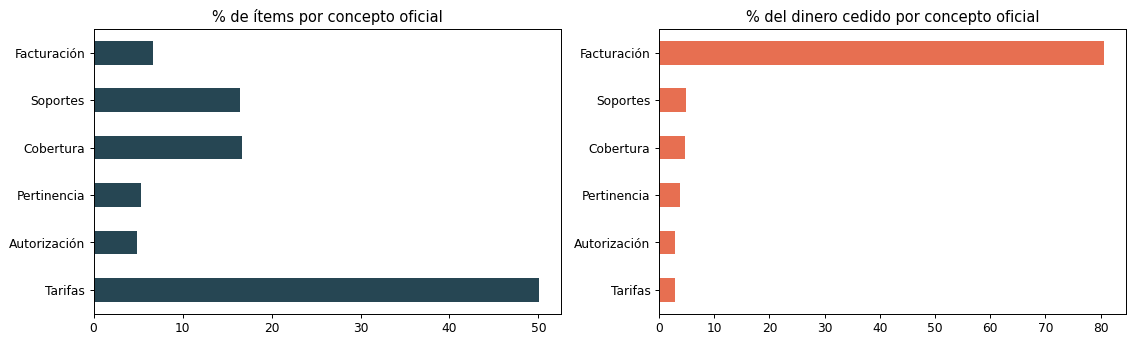

In [5]:
if (RAIZ / "data/procesados/dataset_glosas_limpio.csv").is_file():
    import matplotlib.pyplot as plt
    (RAIZ / "reports/figures").mkdir(parents=True, exist_ok=True)
    df = mm.agregar_concepto_general(df, mapa)
    df["no_recuperada"] = (df["Recuperada"] == "No recuperada").astype(int)
    tab = df.groupby("concepto_general").agg(items=("no_recuperada", "size"), tasa_no_rec=("no_recuperada", "mean"),
                                             cedido=("Valor Aceptado", "sum"), objetado=("Valor Objeción", "sum"))
    tab["% ítems"] = tab["items"] / tab["items"].sum() * 100
    tab["% dinero cedido"] = tab["cedido"] / tab["cedido"].sum() * 100
    tab["tasa_no_rec"] *= 100
    tab = tab.sort_values("% dinero cedido", ascending=False)
    display(tab[["items", "% ítems", "tasa_no_rec", "% dinero cedido"]].round(2))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    tab["% ítems"].plot.barh(ax=axes[0], color="#264653"); axes[0].set_title("% de ítems por concepto oficial"); axes[0].invert_yaxis()
    tab["% dinero cedido"].plot.barh(ax=axes[1], color="#e76f51"); axes[1].set_title("% del dinero cedido por concepto oficial"); axes[1].invert_yaxis()
    for a in axes: a.set_ylabel("")
    plt.tight_layout(); plt.savefig(RAIZ / "reports/figures/fig14_concepto_oficial.png", dpi=150, bbox_inches="tight"); plt.show()
else:
    print("Cruce hospitalario pendiente del CSV privado.")

## Resultado del cruce hospitalario

Con el catálogo histórico, Tarifas agrupa el 50,03 % de los ítems. Facturación agrupa el 6,69 % y concentra el 80,63 % del dinero cedido. De los 174 motivos distintos, 66 quedaron marcados para revisión experta, equivalentes al 7,8 % de los ítems. La concentración por concepto depende de estas asignaciones.